# Laboratoire : EDA
## Solutionnaire : Bike Sharing Dataset

### Source du jeu de données

**Bike Sharing Dataset - UCI Machine Learning Repository**

Fanaee-T, H. (2013). *Bike Sharing* [Dataset].  
DOI : 10.24432/C5W894

Le fichier utilisé est :

```text
hour.csv
```

Il contient les locations horaires de vélos du système Capital Bikeshare pour 2011 et 2012, avec des informations temporelles et météorologiques.


# 1. Importation des bibliothèques

On utilise :

- **NumPy** pour certains calculs numériques ;
- **Pandas** pour l'exploration et la manipulation des données ;
- **Matplotlib** pour les visualisations ;
- **ipywidgets.interact** pour l'interactivité.

`ipywidgets` est rendu optionnel dans ce corrigé afin que le notebook reste exécutable dans un environnement où le module n'est pas installé.


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from ipywidgets import interact
    WIDGETS_DISPONIBLES = True
except ImportError:
    WIDGETS_DISPONIBLES = False
    print("ipywidgets n'est pas installé. La partie interactive pourra être exécutée après installation.")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")


ipywidgets n'est pas installé. La partie interactive pourra être exécutée après installation.


# 2. Chargement des données

Le fichier `hour.csv` doit être placé dans le même dossier que le notebook.


In [ ]:
df = pd.read_csv("../Code/data/raw/bike_sharing/hour.csv")
df.head()


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.29,0.75,0.00,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.29,0.75,0.00,0,1,1


### Explication enseignant

`read_csv()` charge le fichier dans un `DataFrame`.

`head()` permet de vérifier rapidement :

- que le fichier a été chargé correctement ;
- que les séparateurs ont été reconnus ;
- que les noms de colonnes sont cohérents ;
- que les valeurs semblent plausibles.


# 3. Première exploration

Avant toute transformation, on cherche à comprendre la structure du jeu de données.


In [7]:
lignes, colonnes = df.shape

print(f"Dimensions : {lignes} lignes x {colonnes} colonnes")
print(f"Colonnes : {', '.join(df.columns)}")
print(f"\nTypes :\n{df.dtypes.to_string()}")
print(f"\nValeurs manquantes : {df.isna().sum().sum()}")
print(f"Doublons complets : {df.duplicated().sum()}")


Dimensions : 17379 lignes x 17 colonnes
Colonnes : instant, dteday, season, yr, mnth, hr, holiday, weekday, workingday, weathersit, temp, atemp, hum, windspeed, casual, registered, cnt

Types :
instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64

Valeurs manquantes : 0
Doublons complets : 0


In [8]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


In [9]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
instant,17379.00,8690.00,5017.03,1.00,4345.50,8690.00,13034.50,17379.00
season,17379.00,2.50,1.11,1.00,2.00,3.00,3.00,4.00
yr,17379.00,0.50,0.50,0.00,0.00,1.00,1.00,1.00
mnth,17379.00,6.54,3.44,1.00,4.00,7.00,10.00,12.00
hr,17379.00,11.55,6.91,0.00,6.00,12.00,18.00,23.00
holiday,17379.00,0.03,0.17,0.00,0.00,0.00,0.00,1.00
weekday,17379.00,3.00,2.01,0.00,1.00,3.00,5.00,6.00
workingday,17379.00,0.68,0.47,0.00,0.00,1.00,1.00,1.00
weathersit,17379.00,1.43,0.64,1.00,1.00,1.00,2.00,4.00
temp,17379.00,0.50,0.19,0.02,0.34,0.50,0.66,1.00


## Réponses attendues

### 1. Combien y a-t-il d'observations ?

Le fichier `hour.csv` contient environ **17 400 observations horaires**.

### 2. Combien y a-t-il de variables ?

Le fichier contient **17 colonnes**.

### 3. Quelles variables sont numériques ?

Techniquement, presque toutes les colonnes sont numériques sauf `dteday`.

Cependant, plusieurs variables numériques représentent en réalité des **catégories codées** :

- `season`
- `yr`
- `mnth`
- `hr`
- `holiday`
- `weekday`
- `workingday`
- `weathersit`

C'est une distinction importante : **type informatique** et **nature statistique** ne sont pas la même chose.

### 4. Y a-t-il des valeurs manquantes ?

Non. Le jeu de données UCI indique qu'il ne contient pas de valeurs manquantes.

### 5. Y a-t-il des doublons ?

On s'attend normalement à **0 doublon complet**.

### Point pédagogique

L'absence de valeurs manquantes ne signifie pas que le travail de préparation est inutile. Il faut encore :

- convertir les dates ;
- interpréter les codes ;
- créer des variables dérivées ;
- vérifier le sens des variables.


# 4. Préparation des données

## 4.1 Conversion de `dteday`

La colonne est chargée comme texte. On la convertit en `datetime`.


In [10]:
df["dteday"] = pd.to_datetime(df["dteday"])

print(df["dteday"].dtype)
df[["dteday"]].head()


datetime64[us]


,dteday
0,2011-01-01
1,2011-01-01
2,2011-01-01
3,2011-01-01
4,2011-01-01


### Pourquoi ?

Le type `datetime` permet ensuite d'utiliser facilement :

- `.dt.year`
- `.dt.month`
- `.dt.day_name()`
- des tris chronologiques ;
- des regroupements temporels.


## 4.2 Création de libellés pour les saisons

Les valeurs numériques sont difficiles à interpréter directement dans les tableaux et graphiques.


In [11]:
saisons = {
    1: "Hiver",
    2: "Printemps",
    3: "Été",
    4: "Automne"
}

df["saison"] = df["season"].map(saisons)

df[["season", "saison"]].drop_duplicates().sort_values("season")


,season,saison
0,1,Hiver
1807,2,Printemps
4010,3,Été
6250,4,Automne


## 4.3 Création de libellés pour la météo


In [12]:
meteo = {
    1: "Dégagé / quelques nuages",
    2: "Brume / nuageux",
    3: "Pluie ou neige légère",
    4: "Conditions sévères"
}

df["meteo"] = df["weathersit"].map(meteo)

df[["weathersit", "meteo"]].drop_duplicates().sort_values("weathersit")


,weathersit,meteo
0,1,Dégagé / quelques nuages
5,2,Brume / nuageux
18,3,Pluie ou neige légère
585,4,Conditions sévères


## 4.4 Création d'une période de la journée

On transforme l'heure en quatre catégories plus faciles à comparer.


In [13]:
def determiner_periode(heure):
    if 0 <= heure <= 5:
        return "Nuit"
    elif 6 <= heure <= 11:
        return "Matin"
    elif 12 <= heure <= 17:
        return "Après-midi"
    else:
        return "Soir"

df["periode"] = df["hr"].apply(determiner_periode)

df[["hr", "periode"]].drop_duplicates().sort_values("hr").head(24)


,hr,periode
0,0,Nuit
1,1,Nuit
2,2,Nuit
3,3,Nuit
4,4,Nuit
5,5,Nuit
6,6,Matin
7,7,Matin
8,8,Matin
9,9,Matin


### Explication 

Cette transformation illustre le **feature engineering** :

> On crée une variable nouvelle à partir d'une variable existante afin de faciliter une analyse.

La variable `hr` est plus précise, tandis que `periode` permet une lecture synthétique.


# 5. Statistiques descriptives sur `cnt`

`cnt` représente le nombre total de locations durant une heure.


In [14]:
stats_cnt = pd.Series({
    "Moyenne": df["cnt"].mean(),
    "Médiane": df["cnt"].median(),
    "Minimum": df["cnt"].min(),
    "Maximum": df["cnt"].max(),
    "Écart-type": df["cnt"].std(),
    "Variance": df["cnt"].var(),
    "Q1": df["cnt"].quantile(0.25),
    "Q3": df["cnt"].quantile(0.75)
})

stats_cnt


Moyenne        189.46
Médiane        142.00
Minimum          1.00
Maximum        977.00
Écart-type     181.39
Variance     32901.46
Q1              40.00
Q3             281.00
dtype: float64

## Interprétation de référence

Les valeurs de référence sont approximativement :

- moyenne : **189 locations/heure** ;
- médiane : **142** ;
- minimum : **1** ;
- maximum : **977** ;
- Q1 : **40** ;
- Q3 : **281**.

La moyenne est supérieure à la médiane, ce qui suggère une distribution **asymétrique vers la droite**.

Le maximum est très supérieur aux valeurs centrales. Cela indique la présence de périodes de pointe importantes.

L'écart-type est élevé, ce qui confirme une forte variabilité de la demande selon l'heure et les conditions.


# 6. Analyse par groupes

## 6.1 Nombre moyen de locations par saison


In [15]:
locations_saison = (
    df.groupby("saison")["cnt"]
      .mean()
      .sort_values(ascending=False)
)

locations_saison


saison
Été         236.02
Printemps   208.34
Automne     198.87
Hiver       111.11
Name: cnt, dtype: float64

### Interprétation

La saison correspondant au code `3` (**Été**) présente normalement la moyenne la plus élevée.

Valeurs de référence approximatives :

| Saison | Moyenne |
|---|---:|
| Été | 236 |
| Printemps | 208 |
| Automne | 199 |
| Hiver | 111 |

Cela suggère un effet saisonnier important.

Attention cependant : ce résultat ne permet pas d'affirmer que la saison est **la cause unique** de la demande. D'autres variables évoluent aussi avec les saisons, notamment la température.


## 6.2 Nombre moyen de locations selon l'heure


In [16]:
locations_heure = df.groupby("hr")["cnt"].mean()

locations_heure


hr
0     53.90
1     33.38
2     22.87
3     11.73
4      6.35
5     19.89
6     76.04
7    212.06
8    359.01
9    219.31
10   173.67
11   208.14
12   253.32
13   253.66
14   240.95
15   251.23
16   311.98
17   461.45
18   425.51
19   311.52
20   226.03
21   172.31
22   131.34
23    87.83
Name: cnt, dtype: float64

In [17]:
heure_max = locations_heure.idxmax()
valeur_max = locations_heure.max()

print("Heure de demande moyenne maximale :", heure_max)
print("Nombre moyen de locations :", valeur_max)


Heure de demande moyenne maximale : 17
Nombre moyen de locations : 461.45205479452056


### Interprétation

La demande présente généralement deux pointes caractéristiques :

- une pointe le **matin**, autour des déplacements vers le travail ;
- une pointe plus importante en **fin d'après-midi**, autour de 17 h–18 h.

L'heure **17 h** présente normalement la moyenne la plus élevée.

Ce profil suggère que les déplacements domicile-travail jouent un rôle important dans l'utilisation du service.


## 6.3 Nombre moyen de locations selon les conditions météo


In [18]:
locations_meteo = (
    df.groupby("meteo")["cnt"]
      .mean()
      .sort_values(ascending=False)
)

locations_meteo


meteo
Dégagé / quelques nuages   204.87
Brume / nuageux            175.17
Pluie ou neige légère      111.58
Conditions sévères          74.33
Name: cnt, dtype: float64

### Interprétation

Les conditions **dégagées ou peu nuageuses** sont associées au plus grand nombre moyen de locations.

Lorsque les conditions deviennent moins favorables, la demande diminue généralement.

Cela suggère une association entre météo et utilisation du service, mais il faut rester prudent : saison, température, heure et jour de la semaine peuvent aussi influencer simultanément la demande.


# 7. Filtrage

## 7.1 Les 10 % d'heures les plus achalandées


In [19]:
seuil_90 = df["cnt"].quantile(0.90)

print("90e percentile :", seuil_90)

top_10 = df[df["cnt"] > seuil_90]

print("Nombre d'observations :", len(top_10))

top_10[
    ["dteday", "hr", "saison", "meteo", "workingday", "cnt"]
].head(20)


90e percentile : 451.2000000000007
Nombre d'observations : 1738


,dteday,hr,saison,meteo,workingday,cnt
2323,2011-04-11,17,Printemps,Dégagé / quelques nuages,1,452
2563,2011-04-21,17,Printemps,Dégagé / quelques nuages,1,481
2564,2011-04-21,18,Printemps,Dégagé / quelques nuages,1,452
2659,2011-04-25,17,Printemps,Dégagé / quelques nuages,1,521
2660,2011-04-25,18,Printemps,Dégagé / quelques nuages,1,499
2683,2011-04-26,17,Printemps,Dégagé / quelques nuages,1,521
2684,2011-04-26,18,Printemps,Dégagé / quelques nuages,1,528
2707,2011-04-27,17,Printemps,Pluie ou neige légère,1,521
2731,2011-04-28,17,Printemps,Dégagé / quelques nuages,1,455
2732,2011-04-28,18,Printemps,Dégagé / quelques nuages,1,530


In [20]:
top_10["hr"].value_counts().sort_index()


hr
7      76
8     268
10     15
11     51
12     72
13     74
14     73
15     74
16    134
17    384
18    338
19    147
20     29
21      2
22      1
Name: count, dtype: int64

### Interprétation

Les heures de fin d'après-midi, particulièrement autour de **17 h et 18 h**, sont fortement représentées dans les observations les plus achalandées.

Le filtre permet de passer d'une question générale :

> Quand le service est-il utilisé ?

à une question plus ciblée :

> Quelles caractéristiques retrouve-t-on dans les périodes de très forte demande ?


## 7.2 Forte demande malgré une météo moins favorable


In [21]:
moyenne_cnt = df["cnt"].mean()

forte_demande_mauvaise_meteo = df[
    (df["weathersit"] == 3)
    & (df["cnt"] > moyenne_cnt)
]

print("Nombre d'observations :", len(forte_demande_mauvaise_meteo))

forte_demande_mauvaise_meteo[
    ["dteday", "hr", "temp", "hum", "meteo", "cnt"]
].head(20)


Nombre d'observations : 271


,dteday,hr,temp,hum,meteo,cnt
1871,2011-03-23,18,0.38,0.82,Pluie ou neige légère,238
2105,2011-04-02,14,0.32,0.76,Pluie ou neige légère,190
2243,2011-04-08,8,0.34,0.87,Pluie ou neige légère,221
2338,2011-04-12,8,0.48,0.88,Pluie ou neige légère,226
2347,2011-04-12,17,0.44,0.77,Pluie ou neige légère,291
2348,2011-04-12,18,0.44,0.77,Pluie ou neige légère,224
2579,2011-04-22,9,0.34,0.61,Pluie ou neige légère,195
2637,2011-04-24,19,0.60,0.83,Pluie ou neige légère,194
2707,2011-04-27,17,0.66,0.83,Pluie ou neige légère,521
2708,2011-04-27,18,0.66,0.83,Pluie ou neige légère,412


### Interprétation

Le résultat montre qu'une météo moins favorable **n'empêche pas nécessairement** une forte demande.

C'est une excellente illustration d'un principe important en analyse :

> Une variable peut influencer un phénomène sans l'expliquer à elle seule.

L'heure, le caractère ouvrable du jour et les habitudes de déplacement peuvent compenser en partie l'effet de la météo.


# 8. Détection des valeurs atypiques avec l'IQR


In [22]:
q1 = df["cnt"].quantile(0.25)
q3 = df["cnt"].quantile(0.75)

iqr = q3 - q1

borne_inf = q1 - 1.5 * iqr
borne_sup = q3 + 1.5 * iqr

print("Q1 :", q1)
print("Q3 :", q3)
print("IQR :", iqr)
print("Borne inférieure :", borne_inf)
print("Borne supérieure :", borne_sup)


Q1 : 40.0
Q3 : 281.0
IQR : 241.0
Borne inférieure : -321.5
Borne supérieure : 642.5


In [23]:
atypiques = df[
    (df["cnt"] < borne_inf)
    | (df["cnt"] > borne_sup)
]

print("Nombre de valeurs atypiques :", len(atypiques))

atypiques[
    ["dteday", "hr", "season", "workingday", "weathersit", "cnt"]
].sort_values("cnt", ascending=False).head(20)


Nombre de valeurs atypiques : 505


,dteday,hr,season,workingday,weathersit,cnt
14773,2012-09-12,18,3,1,1,977
14964,2012-09-20,17,3,1,1,976
14748,2012-09-11,17,3,1,1,970
14725,2012-09-10,18,3,1,1,968
15084,2012-09-25,17,4,1,1,967
15780,2012-10-24,17,4,1,1,963
10622,2012-03-23,17,2,1,2,957
15108,2012-09-26,17,4,1,1,953
15444,2012-10-10,17,4,1,1,948
15588,2012-10-16,17,4,1,1,943


## Interprétation

Avec :

- Q1 ≈ **40**
- Q3 ≈ **281**

on obtient :

$$
IQR = 281 - 40 = 241
$$

et une borne supérieure d'environ :

$$
281 + 1.5 \times 241 = 642.5
$$

Les valeurs supérieures à environ **642 locations** sont donc considérées comme atypiques selon cette règle.

### Point essentiel

Une valeur atypique n'est **pas nécessairement une erreur**.

Dans ce contexte, une forte demande peut être parfaitement réelle :

- heure de pointe ;
- journée particulièrement favorable ;
- événement ;
- forte utilisation par les abonnés.

L'IQR sert à **repérer** les observations inhabituelles, pas à décider automatiquement de leur suppression.


# 9. Corrélations


In [24]:
variables_corr = [
    "temp",
    "atemp",
    "hum",
    "windspeed",
    "cnt"
]

correlations = df[variables_corr].corr()

correlations


,temp,atemp,hum,windspeed,cnt
temp,1.00,0.99,-0.07,-0.02,0.40
atemp,0.99,1.00,-0.05,-0.06,0.40
hum,-0.07,-0.05,1.00,-0.29,-0.32
windspeed,-0.02,-0.06,-0.29,1.00,0.09
cnt,0.40,0.40,-0.32,0.09,1.00


In [25]:
correlations["cnt"].sort_values(ascending=False)


cnt          1.00
temp         0.40
atemp        0.40
windspeed    0.09
hum         -0.32
Name: cnt, dtype: float64

## Interprétation de référence

Les corrélations avec `cnt` sont approximativement :

| Variable | Corrélation avec `cnt` |
|---|---:|
| `temp` | +0.405 |
| `atemp` | +0.401 |
| `windspeed` | +0.093 |
| `hum` | -0.323 |

### Lecture

- `temp` présente l'association positive la plus forte parmi ces variables ;
- `hum` présente une association négative modérée ;
- `windspeed` est faiblement associé à la demande.

On remarque également que `temp` et `atemp` sont **très fortement corrélées entre elles**. C'est logique puisqu'elles représentent deux mesures très proches de la température.

### Rappel

Une corrélation :

- mesure une association linéaire ;
- ne démontre pas la causalité ;
- peut être influencée par d'autres variables.


# 10. Visualisations

## 10.1 Profil horaire de la demande


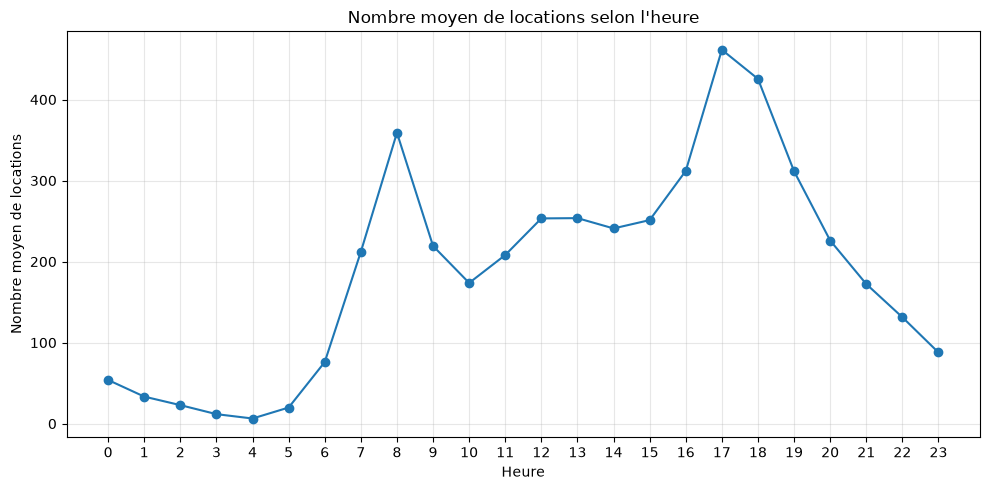

In [26]:
profil_horaire = df.groupby("hr")["cnt"].mean()

plt.figure(figsize=(10, 5))
plt.plot(
    profil_horaire.index,
    profil_horaire.values,
    marker="o"
)

plt.title("Nombre moyen de locations selon l'heure")
plt.xlabel("Heure")
plt.ylabel("Nombre moyen de locations")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Pourquoi ce graphique ?

Une courbe est appropriée parce que l'heure est une variable **ordonnée**.

### Interprétation

Le graphique met en évidence les variations de la demande au cours de la journée. On observe une faible utilisation pendant la nuit, une augmentation le matin et une pointe importante en fin d'après-midi.

Le profil est compatible avec des déplacements liés au travail.


## 10.2 Comparaison des saisons


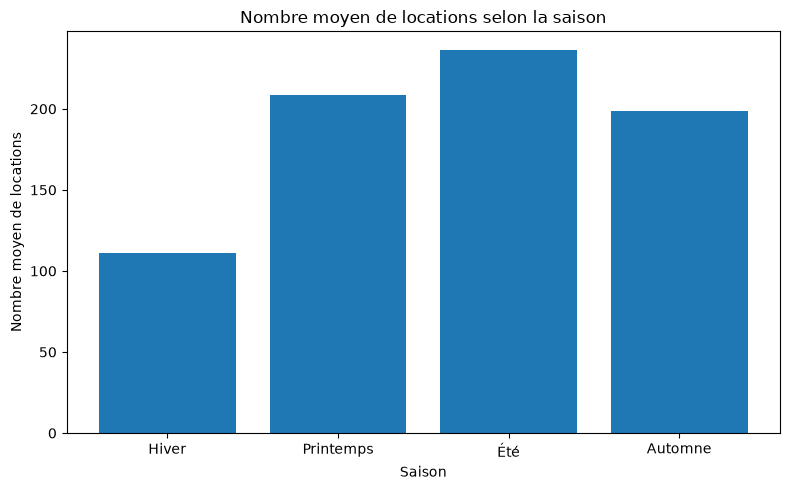

In [27]:
ordre_saisons = ["Hiver", "Printemps", "Été", "Automne"]

moyennes_saisons = (
    df.groupby("saison")["cnt"]
      .mean()
      .reindex(ordre_saisons)
)

plt.figure(figsize=(8, 5))
plt.bar(moyennes_saisons.index, moyennes_saisons.values)

plt.title("Nombre moyen de locations selon la saison")
plt.xlabel("Saison")
plt.ylabel("Nombre moyen de locations")
plt.tight_layout()
plt.show()


### Pourquoi ce graphique ?

Un diagramme à barres est adapté pour comparer des moyennes entre catégories distinctes.

### Interprétation

L'été présente le niveau moyen le plus élevé, alors que l'hiver présente le plus faible. Cela confirme que la demande varie selon la saison.


## 10.3 Distribution de `cnt`


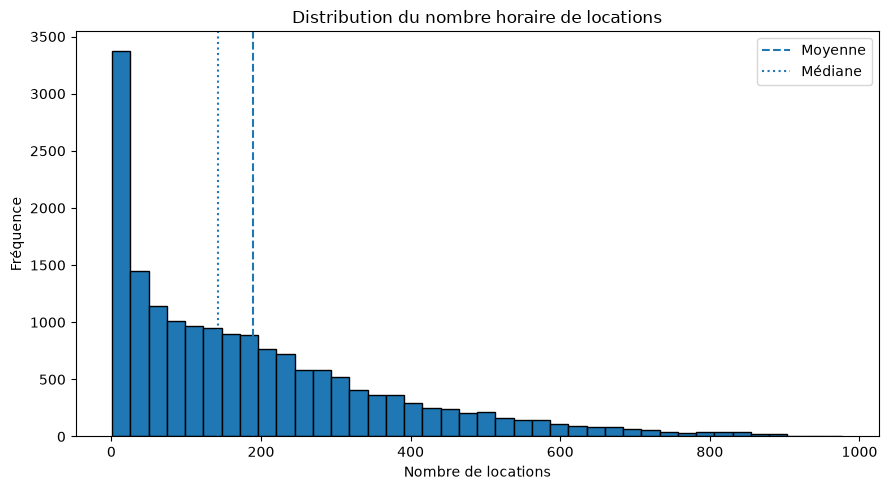

In [28]:
plt.figure(figsize=(9, 5))
plt.hist(df["cnt"], bins=40, edgecolor="black")

plt.axvline(
    df["cnt"].mean(),
    linestyle="--",
    label="Moyenne"
)

plt.axvline(
    df["cnt"].median(),
    linestyle=":",
    label="Médiane"
)

plt.title("Distribution du nombre horaire de locations")
plt.xlabel("Nombre de locations")
plt.ylabel("Fréquence")
plt.legend()
plt.tight_layout()
plt.show()


### Interprétation

La distribution est asymétrique vers la droite.

La majorité des heures présentent une demande relativement faible ou modérée, tandis qu'un nombre plus limité d'heures présentent de très fortes demandes.

Cela explique pourquoi la moyenne est supérieure à la médiane.


## 10.4 Température et nombre de locations


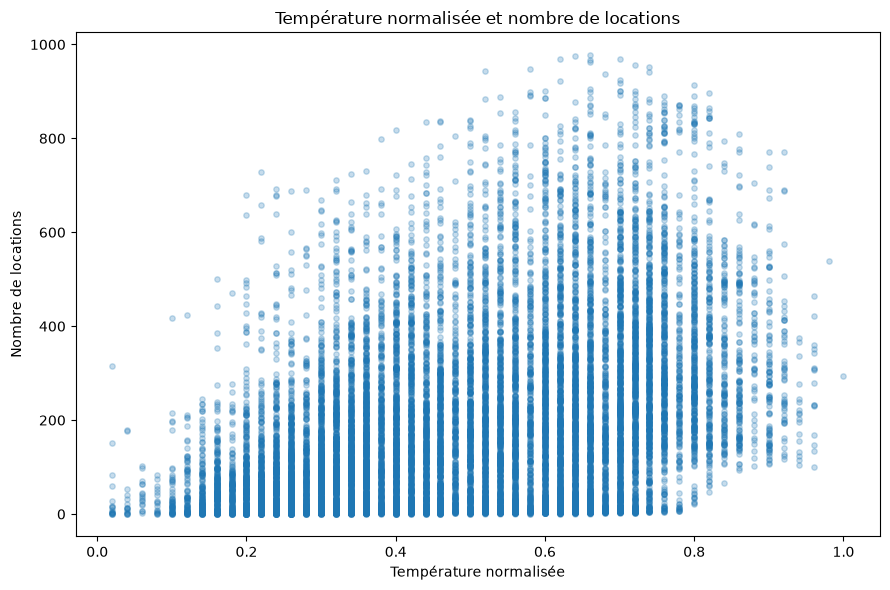

In [29]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["temp"],
    df["cnt"],
    alpha=0.25,
    s=15
)

plt.title("Température normalisée et nombre de locations")
plt.xlabel("Température normalisée")
plt.ylabel("Nombre de locations")
plt.tight_layout()
plt.show()


### Interprétation

On observe globalement davantage de fortes demandes lorsque la température augmente.

Cependant, les points restent très dispersés. La température ne suffit donc pas à expliquer la demande.

Ce graphique est cohérent avec une corrélation positive d'environ **0,40**.


# 11. Visualisation interactive

On souhaite comparer le profil horaire de demande selon la saison.


Exemple statique :


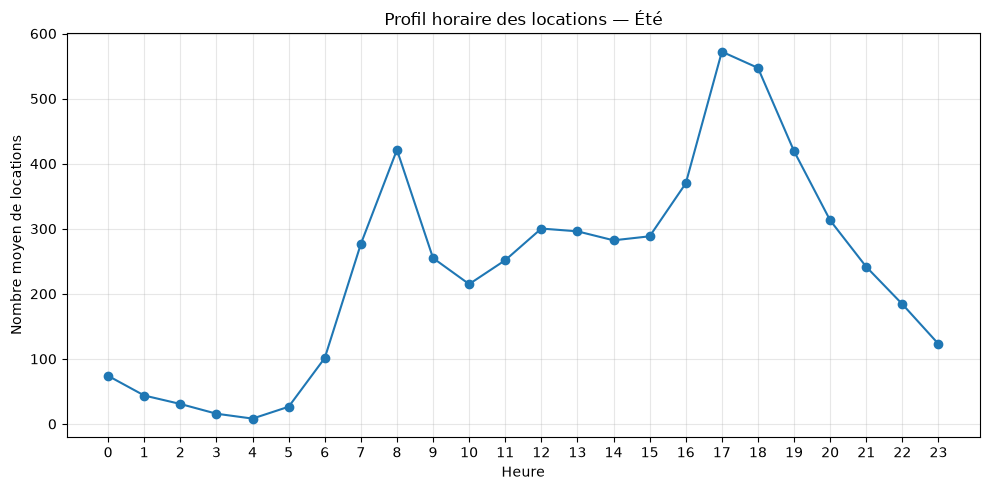

In [30]:
def afficher_saison(saison):
    donnees = df[df["saison"] == saison]

    profil = (
        donnees.groupby("hr")["cnt"]
               .mean()
    )

    plt.figure(figsize=(10, 5))
    plt.plot(
        profil.index,
        profil.values,
        marker="o"
    )

    plt.title(f"Profil horaire des locations — {saison}")
    plt.xlabel("Heure")
    plt.ylabel("Nombre moyen de locations")
    plt.xticks(range(24))
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

if WIDGETS_DISPONIBLES:
    interact(
        afficher_saison,
        saison=sorted(df["saison"].dropna().unique())
    )
else:
    print("Exemple statique :")
    afficher_saison("Été")


## Pourquoi l'interactivité est-elle utile ?

Sans interaction, on devrait créer un graphique différent pour chaque saison.

Avec `interact`, l'utilisateur peut :

1. sélectionner une saison ;
2. conserver le même type de graphique ;
3. comparer rapidement les profils ;
4. explorer les données sans modifier le code.

L'interactivité devient donc un **outil d'exploration**, pas uniquement un effet visuel.


# 12. Mini-synthèse

## 1. À quel moment de la journée la demande semble-t-elle la plus forte ?

La demande est particulièrement élevée en fin d'après-midi, avec une pointe autour de **17 h**. Une seconde pointe apparaît le matin.

## 2. Quelle saison présente la plus forte utilisation moyenne ?

L'**été** présente la plus forte utilisation moyenne.

## 3. Quel rôle les conditions météorologiques semblent-elles jouer ?

La demande est généralement plus forte lorsque les conditions sont dégagées et diminue lorsque la météo se détériore.

Cependant, la météo ne suffit pas à elle seule à expliquer la demande.

## 4. Quelle recommandation peut-on faire au gestionnaire ?

Le gestionnaire devrait prévoir davantage de vélos disponibles durant les **heures de pointe**, particulièrement en fin d'après-midi, et ajuster la disponibilité selon la saison et les prévisions météorologiques.

Une stratégie encore meilleure consisterait à combiner :

- heure ;
- saison ;
- jour ouvrable ;
- météo ;

pour anticiper la demande.


# 13. Conclusion

L'analyse exploratoire montre que la demande du service de vélos varie fortement selon l'heure, la saison et les conditions météorologiques. Les heures de déplacement domicile-travail semblent particulièrement importantes, avec une forte pointe en fin d'après-midi. L'été est associé au plus grand nombre moyen de locations, tandis que l'hiver présente une demande plus faible. La température est positivement associée à la demande, alors que l'humidité présente une relation négative. Certaines valeurs très élevées sont détectées comme atypiques, mais elles peuvent représenter de véritables périodes de pointe plutôt que des erreurs. Une analyse supplémentaire pourrait comparer directement les utilisateurs occasionnels et les utilisateurs enregistrés afin de déterminer si leurs comportements diffèrent selon l'heure et les jours ouvrables.


# Résultats de référence rapides

| Élément | Résultat attendu approximatif |
|---|---|
| Nombre d'observations | ~17 400 |
| Valeurs manquantes | 0 |
| Doublons complets | 0 |
| Moyenne de `cnt` | ~189 |
| Médiane de `cnt` | 142 |
| Maximum de `cnt` | 977 |
| Q1 | 40 |
| Q3 | 281 |
| Saison moyenne la plus élevée | Été |
| Heure moyenne la plus élevée | 17 h |
| Corrélation `temp` / `cnt` | ~+0.405 |
| Corrélation `hum` / `cnt` | ~-0.323 |
| Borne IQR supérieure pour `cnt` | ~642.5 |

> Les valeurs précises doivent toujours être obtenues par exécution du fichier `hour.csv`.
